OrderedDict({'rz': 7, 'cx': 6})
global phase: π/8
                                                                       »
q_0: ───────────────────■────────────────────────────────■───────■─────»
                        │                  ┌─────────┐   │     ┌─┴─┐   »
q_1: ──■────────────────┼───────────────■──┤ Rz(π/4) ├───┼─────┤ X ├───»
     ┌─┴─┐┌──────────┐┌─┴─┐┌─────────┐┌─┴─┐├─────────┴┐┌─┴─┐┌──┴───┴──┐»
q_2: ┤ X ├┤ Rz(-π/4) ├┤ X ├┤ Rz(π/4) ├┤ X ├┤ Rz(-π/4) ├┤ X ├┤ Rz(π/4) ├»
     └───┘└──────────┘└───┘└─────────┘└───┘└──────────┘└───┘└─────────┘»
«     ┌─────────┐      
«q_0: ┤ Rz(π/4) ├───■──
«     ├─────────┴┐┌─┴─┐
«q_1: ┤ Rz(-π/4) ├┤ X ├
«     └──────────┘└───┘
«q_2: ─────────────────
«                      


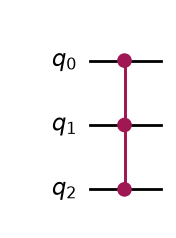

In [55]:
from qiskit import QuantumCircuit, transpile

basis = ['cx', 'id', 'rz', 'sx', 'x']

ccz_circuit = QuantumCircuit(3)
ccz_circuit.ccz(0, 1, 2)

compiled = transpile(
    ccz_circuit,
    basis_gates=basis,
    optimization_level=3
)

print(compiled.count_ops())
print(compiled.draw())

ccz_circuit.draw('mpl')


In [39]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import RCCXGate
import numpy as np

# ==========================================
# 1. STANDARD CIRCUIT (Your Baseline)
# ==========================================
qc_std = QuantumCircuit(3, 3)

# Initialization
for i in range(3): 
    qc_std.h(i)
qc_std.barrier()

# Standard Oracle (using standard Toffoli which costs 6 CX)
qc_std.h(2)
qc_std.ccx(0, 1, 2)
qc_std.h(2)
qc_std.barrier()

# Standard Diffuser
for i in range(3): 
    qc_std.h(i)
    qc_std.x(i)
qc_std.h(2)
qc_std.ccx(0, 1, 2)
qc_std.h(2)
for i in range(3): 
    qc_std.x(i)
    qc_std.h(i)
qc_std.measure([0,1,2], [0,1,2])

# ==========================================
# 2. OPTIMIZED CIRCUIT (Kumar et al. Phase/Ry approach)
# ==========================================
qc_opt = QuantumCircuit(3, 3)

# Initialization (Ry instead of H)
for i in range(3): 
    qc_opt.ry(np.pi/2, i)
qc_opt.barrier()

# Optimized Oracle using Relative-Phase Toffoli (costs only 3 CX)
qc_opt.h(2)
qc_opt.append(RCCXGate(), [0, 1, 2])
qc_opt.h(2)
qc_opt.barrier()

# Optimized Diffuser
for i in range(3):
    qc_opt.ry(np.pi/2, i)
    qc_opt.rz(np.pi, i)

qc_opt.h(2)
qc_opt.append(RCCXGate(), [0, 1, 2])
qc_opt.h(2)

for i in range(3):
    qc_opt.ry(-np.pi/2, i)
    qc_opt.rz(-np.pi, i)
qc_opt.measure([0,1,2], [0,1,2])

# ==========================================
# 3. TRANSPILE AND COMPARE METRICS
# ==========================================
basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

trans_std = transpile(qc_std, basis_gates=basis_gates, optimization_level=2)
trans_opt = transpile(qc_opt, basis_gates=basis_gates, optimization_level=2)

print("--- STANDARD CIRCUIT METRICS ---")
print("Depth:", trans_std.depth())
print("Gates:", dict(trans_std.count_ops()))

print("\n--- OPTIMIZED CIRCUIT METRICS ---")
print("Depth:", trans_opt.depth())
print("Gates:", dict(trans_opt.count_ops()))

--- STANDARD CIRCUIT METRICS ---
Depth: 33
Gates: {'rz': 31, 'cx': 12, 'sx': 11, 'x': 3, 'measure': 3, 'barrier': 2}

--- OPTIMIZED CIRCUIT METRICS ---
Depth: 34
Gates: {'rz': 28, 'sx': 15, 'cx': 6, 'measure': 3, 'barrier': 2, 'x': 1}


In [40]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import RCCXGate
from qiskit_aer import AerSimulator

qc_2_iter_rccx = QuantumCircuit(3, 3)

# ==========================================
# INITIALIZATION
# ==========================================
for i in range(3):
    qc_2_iter_rccx.h(i)
qc_2_iter_rccx.barrier()

# ==========================================
# ITERATION 1
# ==========================================
# RCCX Oracle
qc_2_iter_rccx.h(2)
qc_2_iter_rccx.append(RCCXGate(), [0, 1, 2])
qc_2_iter_rccx.h(2)
qc_2_iter_rccx.barrier()

# RCCX Diffuser 
for i in range(3):
    qc_2_iter_rccx.h(i)
    qc_2_iter_rccx.x(i)

qc_2_iter_rccx.h(2)
qc_2_iter_rccx.append(RCCXGate(), [0, 1, 2]) 
qc_2_iter_rccx.h(2)

for i in range(3):
    qc_2_iter_rccx.x(i)
    qc_2_iter_rccx.h(i)
qc_2_iter_rccx.barrier()

# ==========================================
# ITERATION 2
# ==========================================
# RCCX Oracle
qc_2_iter_rccx.h(2)
qc_2_iter_rccx.append(RCCXGate(), [0, 1, 2])
qc_2_iter_rccx.h(2)
qc_2_iter_rccx.barrier()

# RCCX Diffuser 
for i in range(3):
    qc_2_iter_rccx.h(i)
    qc_2_iter_rccx.x(i)

qc_2_iter_rccx.h(2)
qc_2_iter_rccx.append(RCCXGate(), [0, 1, 2]) 
qc_2_iter_rccx.h(2)

for i in range(3):
    qc_2_iter_rccx.x(i)
    qc_2_iter_rccx.h(i)
qc_2_iter_rccx.barrier()

# ==========================================
# MEASURE & VERIFY
# ==========================================
qc_2_iter_rccx.measure([0,1,2], [0,1,2])

ideal_sim = AerSimulator()
trans_2_iter_rccx = transpile(qc_2_iter_rccx, ideal_sim, optimization_level=3)
job = ideal_sim.run(trans_2_iter_rccx, shots=1024)
counts = job.result().get_counts()

print("Measurement Counts (2 Iterations RCCX):", counts)
print("Target '111' Probability:", counts.get('111', 0) / 1024)

Measurement Counts (2 Iterations RCCX): {'100': 156, '011': 107, '010': 183, '000': 186, '110': 210, '101': 99, '111': 42, '001': 41}
Target '111' Probability: 0.041015625


Measurement Counts (Kumar 2 Iterations): {'111': 962, '000': 8, '001': 13, '101': 10, '011': 7, '100': 7, '010': 11, '110': 6}
Target '111' Probability: 0.939453125


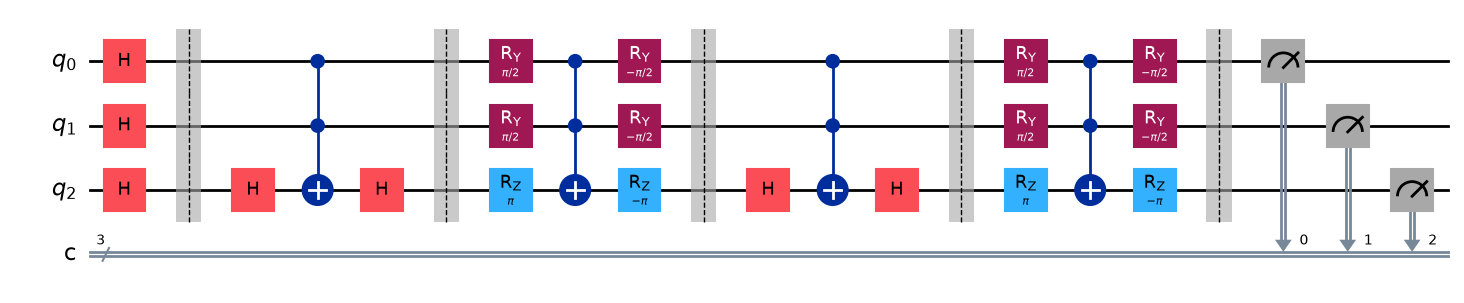

In [41]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import numpy as np

qc_kumar_2_iter = QuantumCircuit(3, 3)

# ==========================================
# INITIALIZATION
# ==========================================
for i in range(3):
    qc_kumar_2_iter.h(i)
qc_kumar_2_iter.barrier()

# ==========================================
# ITERATION 1
# ==========================================
# Standard Oracle
qc_kumar_2_iter.h(2)
qc_kumar_2_iter.ccx(0, 1, 2)
qc_kumar_2_iter.h(2)
qc_kumar_2_iter.barrier()

# Kumar's Optimized Diffuser (Exact CCX, Merged Rotations)
qc_kumar_2_iter.ry(np.pi/2, 0)
qc_kumar_2_iter.ry(np.pi/2, 1)
qc_kumar_2_iter.rz(np.pi, 2)

qc_kumar_2_iter.ccx(0, 1, 2)  # <-- Unmodified multi-controlled NOT

qc_kumar_2_iter.ry(-np.pi/2, 0)
qc_kumar_2_iter.ry(-np.pi/2, 1)
qc_kumar_2_iter.rz(-np.pi, 2)
qc_kumar_2_iter.barrier()

# ==========================================
# ITERATION 2
# ==========================================
# Standard Oracle
qc_kumar_2_iter.h(2)
qc_kumar_2_iter.ccx(0, 1, 2)
qc_kumar_2_iter.h(2)
qc_kumar_2_iter.barrier()

# Kumar's Optimized Diffuser (Exact CCX, Merged Rotations)
qc_kumar_2_iter.ry(np.pi/2, 0)
qc_kumar_2_iter.ry(np.pi/2, 1)
qc_kumar_2_iter.rz(np.pi, 2)

qc_kumar_2_iter.ccx(0, 1, 2)  

qc_kumar_2_iter.ry(-np.pi/2, 0)
qc_kumar_2_iter.ry(-np.pi/2, 1)
qc_kumar_2_iter.rz(-np.pi, 2)
qc_kumar_2_iter.barrier()

# ==========================================
# MEASURE & VERIFY
# ==========================================
qc_kumar_2_iter.measure([0,1,2], [0,1,2])

ideal_sim = AerSimulator()
trans_kumar = transpile(qc_kumar_2_iter, ideal_sim)
job = ideal_sim.run(trans_kumar, shots=1024)
counts = job.result().get_counts()

print("Measurement Counts (Kumar 2 Iterations):", counts)
print("Target '111' Probability:", counts.get('111', 0) / 1024)

trans_kumar.draw('mpl')

In [42]:
from qiskit import transpile

# Define hardware basis gates
basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

# Transpile circuit to basis gates
transpiled_qc = transpile(qc_kumar_2_iter, basis_gates=basis_gates, optimization_level=3)

# Display CNOT overhead and circuit depth
cnot_count = transpiled_qc.count_ops().get('cx', 0)
depth = transpiled_qc.depth()

print(f"CNOT Count: {cnot_count}")
print(f"Circuit Depth: {depth}")

CNOT Count: 24
Circuit Depth: 60


In [43]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import RCCXGate
from qiskit_aer import AerSimulator

# Initialize 3 qubits and 3 classical bits
qc_rccx_oracle = QuantumCircuit(3, 3)

# ==========================================
# INITIALIZATION
# ==========================================
for i in range(3):
    qc_rccx_oracle.h(i)
qc_rccx_oracle.barrier()

# ==========================================
# 2 ITERATIONS (RCCX Oracle + Normal Diffuser)
# ==========================================
for _ in range(2):
    # 1. RCCX Oracle (Reduced overhead, introduces relative phases)
    qc_rccx_oracle.h(2)
    qc_rccx_oracle.append(RCCXGate(), [0, 1, 2])
    qc_rccx_oracle.h(2)
    qc_rccx_oracle.barrier()

    # 2. Normal Diffuser (Exact CCX logic)
    for i in range(3):
        qc_rccx_oracle.h(i)
        qc_rccx_oracle.x(i)

    qc_rccx_oracle.h(2)
    qc_rccx_oracle.ccx(0, 1, 2) 
    qc_rccx_oracle.h(2)

    for i in range(3):
        qc_rccx_oracle.x(i)
        qc_rccx_oracle.h(i)
    qc_rccx_oracle.barrier()

# ==========================================
# MEASURE & VERIFY
# ==========================================
qc_rccx_oracle.measure([0, 1, 2], [0, 1, 2])

# Run on the ideal simulator to see the mathematical effect
ideal_sim = AerSimulator()
trans_qc = transpile(qc_rccx_oracle, ideal_sim)
job = ideal_sim.run(trans_qc, shots=1024)
counts = job.result().get_counts()

print("Measurement Counts (RCCX Oracle + Normal Diffuser):", counts)
print("Target '111' Probability:", counts.get('111', 0) / 1024)

Measurement Counts (RCCX Oracle + Normal Diffuser): {'011': 470, '111': 503, '110': 10, '010': 8, '100': 6, '000': 8, '001': 12, '101': 7}
Target '111' Probability: 0.4912109375


Measurement Counts (RCCX Oracle + Kumar Diffuser): {'011': 489, '111': 496, '100': 9, '000': 6, '010': 9, '101': 8, '110': 3, '001': 4}
Target '111' Probability: 0.484375


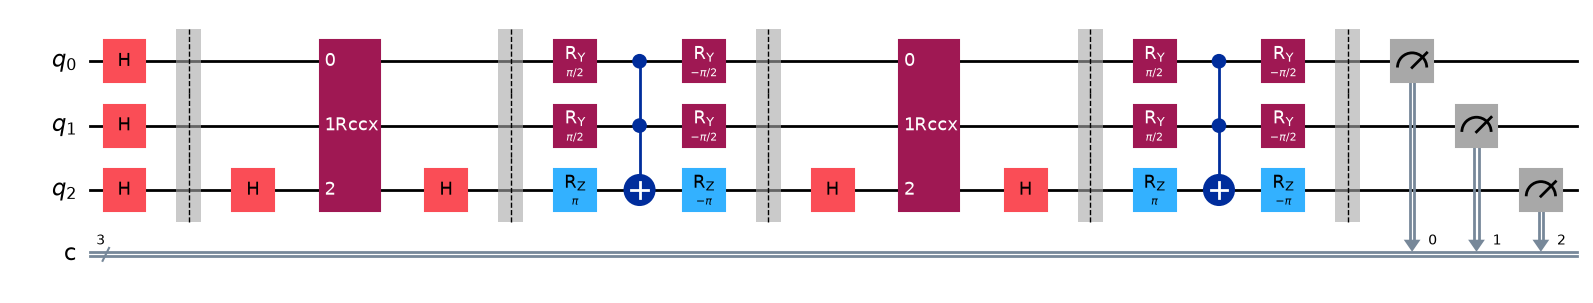

In [44]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import RCCXGate
from qiskit_aer import AerSimulator
import numpy as np

qc_fully_optimized = QuantumCircuit(3, 3)

# ==========================================
# INITIALIZATION
# ==========================================
for i in range(3):
    qc_fully_optimized.h(i)
qc_fully_optimized.barrier()

# ==========================================
# 2 ITERATIONS (RCCX Oracle + Kumar Diffuser)
# ==========================================
for _ in range(2):
    # 1. RCCX Oracle (Reduces 2-qubit gate overhead)
    qc_fully_optimized.h(2)
    qc_fully_optimized.append(RCCXGate(), [0, 1, 2])
    qc_fully_optimized.h(2)
    qc_fully_optimized.barrier()

    # 2. Kumar Diffuser (Minimizes single-qubit depth)
    qc_fully_optimized.ry(np.pi/2, 0)
    qc_fully_optimized.ry(np.pi/2, 1)
    qc_fully_optimized.rz(np.pi, 2)
    
    qc_fully_optimized.ccx(0, 1, 2) 
    
    qc_fully_optimized.ry(-np.pi/2, 0)
    qc_fully_optimized.ry(-np.pi/2, 1)
    qc_fully_optimized.rz(-np.pi, 2)
    qc_fully_optimized.barrier()

# ==========================================
# MEASURE & VERIFY
# ==========================================
qc_fully_optimized.measure([0, 1, 2], [0, 1, 2])

# Run on the ideal simulator to capture baseline algorithmic probabilities
ideal_sim = AerSimulator()
trans_qc = transpile(qc_fully_optimized, ideal_sim)
job = ideal_sim.run(trans_qc, shots=1024)
counts = job.result().get_counts()

print("Measurement Counts (RCCX Oracle + Kumar Diffuser):", counts)
print("Target '111' Probability:", counts.get('111', 0) / 1024)

qc_fully_optimized.draw('mpl')

In [45]:
from qiskit import transpile

# Define hardware basis gates
basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

# Transpile circuit to basis gates
transpiled_qc = transpile(qc_fully_optimized, basis_gates=basis_gates, optimization_level=3)

# Display CNOT overhead and circuit depth
cnot_count = transpiled_qc.count_ops().get('cx', 0)
depth = transpiled_qc.depth()

print(f"CNOT Count: {cnot_count}")
print(f"Circuit Depth: {depth}")

CNOT Count: 18
Circuit Depth: 54


In [46]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# Initialize the Noisy Hardware Simulator
fake_backend = FakeManilaV2()
noisy_sim = AerSimulator.from_backend(fake_backend)
shots = 1024

In [47]:


# Transpile for hardware execution
trans_hyb = transpile(qc_kumar_2_iter, noisy_sim, optimization_level=3)

# Execute and get counts
job_hyb = noisy_sim.run(trans_hyb, shots=shots)
counts_hyb = job_hyb.result().get_counts()

print("=== 2. STD ORACLE + KUMAR DIFFUSER ===")
print("Measurement Counts:", counts_hyb)
print(f"Target '111' Probability: {counts_hyb.get('111', 0) / shots:.3f}\n")

=== 2. STD ORACLE + KUMAR DIFFUSER ===
Measurement Counts: {'111': 594, '000': 35, '110': 130, '011': 57, '101': 66, '010': 39, '001': 43, '100': 60}
Target '111' Probability: 0.580



In [48]:


# Transpile for hardware execution
trans_rccx = transpile(qc_fully_optimized, noisy_sim, optimization_level=3)

# Execute and get counts
job_rccx = noisy_sim.run(trans_rccx, shots=shots)
counts_rccx = job_rccx.result().get_counts()

print("=== 3. RCCX ORACLE + KUMAR DIFFUSER ===")
print("Measurement Counts:", counts_rccx)
print(f"Target '111' Probability: {counts_rccx.get('111', 0) / shots:.3f}\n")

=== 3. RCCX ORACLE + KUMAR DIFFUSER ===
Measurement Counts: {'001': 35, '011': 428, '100': 22, '111': 369, '110': 43, '101': 50, '010': 49, '000': 28}
Target '111' Probability: 0.360



Ancilla RCCX Measurement Counts: {'111': 961, '010': 6, '101': 13, '011': 10, '000': 9, '100': 10, '110': 6, '001': 9}
Target '111' Probability: 0.9384765625


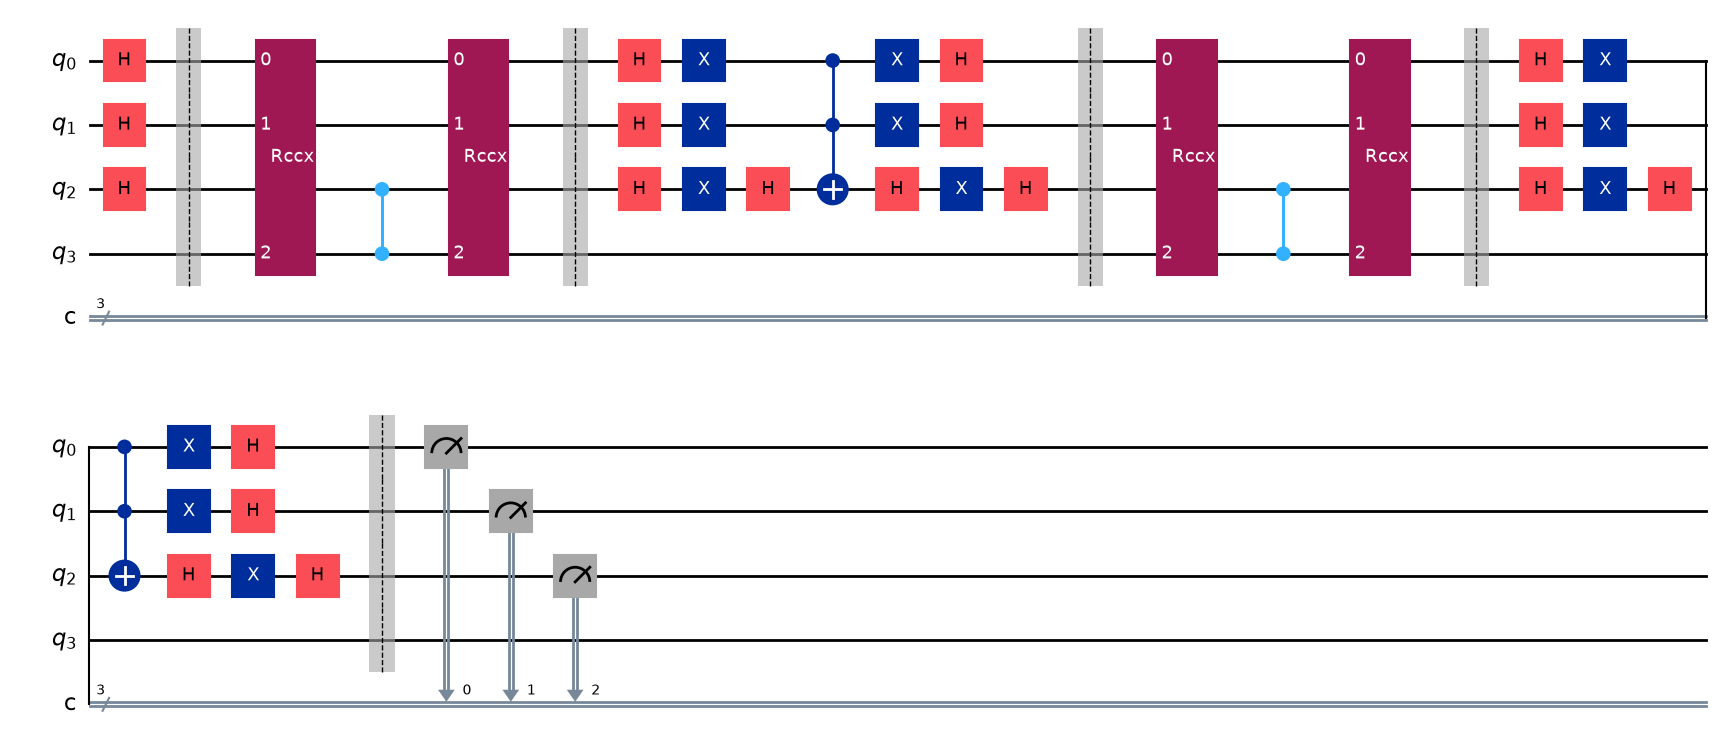

In [49]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# 4 Qubits: q[0], q[1], q[2] are data qubits; q[3] is the ancilla
qc_ancilla = QuantumCircuit(4, 3)

# 1. INITIAL SUPERPOSITION (Data Qubits Only)
qc_ancilla.h([0, 1, 2])
qc_ancilla.barrier()

# ==========================================
# 1 ITERATION (Optimal for 3-qubit search)
# ==========================================

# A. ANCILLA-ASSISTED RCCX ORACLE
# Step 1: Compute control overlap onto Ancilla
qc_ancilla.append(RCCXGate(), [0, 1, 3])
# Step 2: Apply exact phase flip onto target q[2]
qc_ancilla.cz(3, 2)
# Step 3: Uncompute Ancilla to clean up relative phase leakage
qc_ancilla.append(RCCXGate(), [0, 1, 3])
qc_ancilla.barrier()

# B. STANDARD / KUMAR DIFFUSER (Data Qubits Only)
qc_ancilla.h([0, 1, 2])
qc_ancilla.x([0, 1, 2])
qc_ancilla.h(2)
qc_ancilla.ccx(0, 1, 2)
qc_ancilla.h(2)
qc_ancilla.x([0, 1, 2])
qc_ancilla.h([0, 1, 2])
qc_ancilla.barrier()

#iteration 2
# Step 1: Compute control overlap onto Ancilla
qc_ancilla.append(RCCXGate(), [0, 1, 3])
# Step 2: Apply exact phase flip onto target q[2]
qc_ancilla.cz(3, 2)
# Step 3: Uncompute Ancilla to clean up relative phase leakage
qc_ancilla.append(RCCXGate(), [0, 1, 3])
qc_ancilla.barrier()

# B. STANDARD / KUMAR DIFFUSER (Data Qubits Only)
qc_ancilla.h([0, 1, 2])
qc_ancilla.x([0, 1, 2])
qc_ancilla.h(2)
qc_ancilla.ccx(0, 1, 2)
qc_ancilla.h(2)
qc_ancilla.x([0, 1, 2])
qc_ancilla.h([0, 1, 2])
qc_ancilla.barrier()

# 2. MEASURE DATA QUBITS
qc_ancilla.measure([0, 1, 2], [0, 1, 2])

# Run on Ideal AerSimulator
sim = AerSimulator()
trans_qc = transpile(qc_ancilla, sim)
counts = sim.run(trans_qc, shots=1024).result().get_counts()

print("Ancilla RCCX Measurement Counts:", counts)
print("Target '111' Probability:", counts.get('111', 0) / 1024)

qc_ancilla.draw('mpl')

In [50]:
from qiskit import transpile

# Define hardware basis gates
basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

# Transpile circuit to basis gates
transpiled_qc = transpile(qc_ancilla, basis_gates=basis_gates, optimization_level=3)

# Display CNOT overhead and circuit depth
cnot_count = transpiled_qc.count_ops().get('cx', 0)
depth = transpiled_qc.depth()

print(f"CNOT Count: {cnot_count}")
print(f"Circuit Depth: {depth}")

CNOT Count: 26
Circuit Depth: 86


In [51]:


# Transpile for hardware execution
trans_rccx = transpile(qc_ancilla, noisy_sim, optimization_level=3)

# Execute and get counts
job_rccx = noisy_sim.run(trans_rccx, shots=shots)
counts_rccx = job_rccx.result().get_counts()

print("=== 3. RCCX ORACLE + KUMAR DIFFUSER+ancilla===")
print("Measurement Counts:", counts_rccx)
print(f"Target '111' Probability: {counts_rccx.get('111', 0) / shots:.3f}\n")

=== 3. RCCX ORACLE + KUMAR DIFFUSER+ancilla===
Measurement Counts: {'011': 110, '111': 568, '000': 52, '010': 54, '110': 70, '101': 64, '001': 56, '100': 50}
Target '111' Probability: 0.555

